# Cycle-accurate model of the 4×4 systolic array (`rtl_model.py`)

This notebook is a Python copy of the hardware in `top.v` and `pe.v`. It keeps one variable for
every register (accumulators, forwarding registers, edge/skew registers, clear signal) and updates
them **once per clock edge**, exactly like the Verilog. Every result is compared with NumPy's `A @ B`.

**No FPGA board is needed.** Run the cells from top to bottom (*Kernel → Restart & Run All*).

| Section | What it shows |
|---|---|
| 1 | Settings and 32-bit wrap-around |
| 2 | The cycle-by-cycle simulation |
| 3 | Wavefront trace (which k each PE uses in each cycle) |
| 4 | 10 002 checks against NumPy (Table 3.1 of the report) |
| 5 | Search for the smallest RUN window (3N) |
| 6 | Heat-map of the wavefront |

## 1. Settings

`N` is the array size and `RUN_CYCLES` is the length of the RUN window used by `top.v` (3N + 4 = 16).
To model the 8×8 design, set `N = 8` and `RUN_CYCLES = 28`.

In [1]:
import numpy as np

N = 4
RUN_CYCLES = 3 * N + 4      # 16 for 4x4, 28 for 8x8
print(f"N = {N}, RUN window = {RUN_CYCLES} cycles, array activity = {3*N-2} cycles")

N = 4, RUN window = 16 cycles, array activity = 10 cycles


`to_i32` wraps a Python integer to a signed 32-bit value, which is what the 32-bit accumulator
register does in hardware (Python integers never overflow on their own).

In [2]:
def to_i32(x):
    x &= 0xFFFFFFFF
    return x - (1 << 32) if x & 0x80000000 else x

print(to_i32(2**31), to_i32(-1), to_i32(65536))

-2147483648 -1 65536


## 2. The simulation

Each pass of the `for t` loop is **one clock cycle of the RUN state**:

1. **PE inputs (combinational):** PE(i,0) takes `a_edge[i]`, every other PE takes `a_out` of its left
   neighbour. PE(0,j) takes `b_edge[j]`, every other PE takes `b_out` of the PE above.
2. **Clock edge, PEs:** `acc += a_in*b_in`, `a_out = a_in`, `b_out = b_in` (Eq. 2.1), or all zeros while
   `arr_clr` is high.
3. **Clock edge, edge registers:** the skew rule `a_edge[i] = A[i][t-i]`, `b_edge[j] = B[t-j][j]`, zero
   outside the window (Eq. 2.2).

All new values are computed from the old ones before anything is overwritten, the same as Verilog's
non-blocking `<=`. The accumulators start at **12345** (garbage from a previous job) to prove that the
clear step works. The *tags* only record which index k a value carries, for the trace in Section 3.

In [3]:
def simulate(A, B, run_cycles=None, trace=False):
    run_cycles = RUN_CYCLES if run_cycles is None else run_cycles
    mat = list(A.flatten()) + list(B.flatten())        # operand store: A then B, row-major
    a_edge = [0] * N
    b_edge = [0] * N
    a_out = [[0] * N for _ in range(N)]
    b_out = [[0] * N for _ in range(N)]
    acc = [[12345] * N for _ in range(N)]              # garbage from a previous job
    a_tag, b_tag = [None] * N, [None] * N
    a_out_tag = [[None] * N for _ in range(N)]
    b_out_tag = [[None] * N for _ in range(N)]
    rows = []

    arr_clr = 1                                        # S_CLR: clear is high in the first cycle
    for t in range(run_cycles):
        # ---- combinational: inputs of every PE ----
        a_in = [[a_edge[i] if j == 0 else a_out[i][j-1] for j in range(N)] for i in range(N)]
        b_in = [[b_edge[j] if i == 0 else b_out[i-1][j] for j in range(N)] for i in range(N)]
        ai_t = [[a_tag[i] if j == 0 else a_out_tag[i][j-1] for j in range(N)] for i in range(N)]
        bi_t = [[b_tag[j] if i == 0 else b_out_tag[i-1][j] for j in range(N)] for i in range(N)]
        if trace:
            rows.append((t, [[ai_t[i][j] if ai_t[i][j] is not None and ai_t[i][j] == bi_t[i][j]
                              else ('X' if (ai_t[i][j] is not None or bi_t[i][j] is not None) else '.')
                              for j in range(N)] for i in range(N)]))

        # ---- clock edge: PE registers (pe.v) ----
        for i in range(N):
            for j in range(N):
                if arr_clr:
                    acc[i][j], a_out[i][j], b_out[i][j] = 0, 0, 0
                    a_out_tag[i][j] = b_out_tag[i][j] = None
                else:
                    acc[i][j] = to_i32(acc[i][j] + a_in[i][j] * b_in[i][j])
                    a_out[i][j], b_out[i][j] = a_in[i][j], b_in[i][j]
                    a_out_tag[i][j], b_out_tag[i][j] = ai_t[i][j], bi_t[i][j]

        # ---- clock edge: edge (skew) registers (top.v, S_RUN) ----
        for i in range(N):
            if i <= t < i + N:
                a_edge[i] = int(mat[N*i + (t - i)])            # A[i][t-i]
                b_edge[i] = int(mat[N*N + N*(t - i) + i])      # B[t-i][i]
                a_tag[i] = b_tag[i] = t - i
            else:
                a_edge[i] = b_edge[i] = 0
                a_tag[i] = b_tag[i] = None
        arr_clr = 0
    return np.array(acc), rows

A quick single test with small numbers, so the result can be checked by eye:

In [4]:
rng = np.random.default_rng(1)
A = rng.integers(-10, 10, (N, N))
B = rng.integers(-10, 10, (N, N))
C, _ = simulate(A, B)
print("A =\n", A, "\n\nB =\n", B)
print("\nModel C =\n", C, "\n\nNumPy A@B =\n", A @ B)
print("\nMATCH" if np.array_equal(C, A @ B) else "\nMISMATCH")

A =
 [[ -1   0   5   9]
 [-10  -8   6   8]
 [ -6  -4   7  -2]
 [ -5   6  -5  -2]] 

B =
 [[  2   0  -9 -10]
 [  7   5   6   0]
 [  6  -4  -1   5]
 [ -8  -4  -8  -1]]

Model C =
 [[ -44  -56  -68   26]
 [-104  -96  -28  122]
 [  18  -40   39   97]
 [  18   58  102   27]] 

NumPy A@B =
 [[ -44  -56  -68   26]
 [-104  -96  -28  122]
 [  18  -40   39   97]
 [  18   58  102   27]]

MATCH


## 3. Wavefront trace

A = 1…16 and B = 2I (so C = 2A). For every cycle the grid shows, for each PE:

* a **number** = the index k of the matching pair A[i][k], B[k][j] the PE adds in that cycle,
* `.` = idle (zeros), `X` = mismatched pair (must never appear).

Rows of the printed grid are separated by `|`. PE(0,0) starts in cycle 1 and PE(3,3) adds its last
product in cycle 10 = 3N − 2, following k = c − 1 − i − j.

In [5]:
A = np.arange(1, N*N + 1).reshape(N, N)
B = np.eye(N, dtype=int) * 2
C, rows = simulate(A, B, trace=True)
for t, grid in rows:
    print(f"cycle {t:2d}: " + " | ".join(" ".join(str(x) for x in r) for r in grid))
print("\nC =\n", C, "\nC == A@B:", np.array_equal(C, A @ B))

cycle  0: . . . . | . . . . | . . . . | . . . .
cycle  1: 0 . . . | . . . . | . . . . | . . . .
cycle  2: 1 0 . . | 0 . . . | . . . . | . . . .
cycle  3: 2 1 0 . | 1 0 . . | 0 . . . | . . . .
cycle  4: 3 2 1 0 | 2 1 0 . | 1 0 . . | 0 . . .
cycle  5: . 3 2 1 | 3 2 1 0 | 2 1 0 . | 1 0 . .
cycle  6: . . 3 2 | . 3 2 1 | 3 2 1 0 | 2 1 0 .
cycle  7: . . . 3 | . . 3 2 | . 3 2 1 | 3 2 1 0
cycle  8: . . . . | . . . 3 | . . 3 2 | . 3 2 1
cycle  9: . . . . | . . . . | . . . 3 | . . 3 2
cycle 10: . . . . | . . . . | . . . . | . . . 3
cycle 11: . . . . | . . . . | . . . . | . . . .
cycle 12: . . . . | . . . . | . . . . | . . . .
cycle 13: . . . . | . . . . | . . . . | . . . .
cycle 14: . . . . | . . . . | . . . . | . . . .
cycle 15: . . . . | . . . . | . . . . | . . . .

C =
 [[ 2  4  6  8]
 [10 12 14 16]
 [18 20 22 24]
 [26 28 30 32]] 
C == A@B: True


## 4. Full check against NumPy (Table 3.1)

Two extreme cases (all −128 × all −128 gives the largest result, 65 536; all +127 × all −128 gives the
most negative one) plus 10 000 random INT8 matrix pairs. This takes about half a minute.

In [6]:
rng = np.random.default_rng(0)
cases = [(np.full((N, N), -128), np.full((N, N), -128)),
         (np.full((N, N), 127),  np.full((N, N), -128))]
n_random = 10000 if N == 4 else 2000
cases += [(rng.integers(-128, 128, (N, N)), rng.integers(-128, 128, (N, N))) for _ in range(n_random)]

bad = 0
for A, B in cases:
    C, _ = simulate(A, B)
    if not np.array_equal(C, A @ B):
        bad += 1
print(f"{len(cases) - bad}/{len(cases)} cycle-accurate checks passed")
print("largest result:", simulate(*cases[0])[0][0, 0], "  most negative:", simulate(*cases[1])[0][0, 0])

10002/10002 cycle-accurate checks passed
largest result: 65536   most negative: -65024


## 5. Smallest RUN window

The same random cases are run with shorter and shorter RUN windows. The window must also include
the cycle that loads the edge registers and the cycle in which `c_reg` copies the results, so the
minimum is 1 + (3N − 2) + 1 = **3N** (12 for 4×4). The design uses 3N + 4 = 16 for margin.

The model returns the accumulators *after* the last edge, while `c_reg` copies them one edge earlier,
so a window of `w` cycles in hardware corresponds to `run_cycles = w - 1` here.

In [7]:
rng = np.random.default_rng(3)
sweep = [(rng.integers(-128, 128, (N, N)), rng.integers(-128, 128, (N, N))) for _ in range(200)]
for w in range(3*N - 3, 3*N + 5):
    ok = all(np.array_equal(simulate(A, B, run_cycles=w - 1)[0], A @ B) for A, B in sweep)
    print(f"RUN window {w:2d} cycles: {'all correct' if ok else 'WRONG results'}"
          + ("   <- minimum (3N)" if w == 3*N else "") + ("   <- used in top.v" if w == RUN_CYCLES else ""))

RUN window  9 cycles: WRONG results
RUN window 10 cycles: WRONG results
RUN window 11 cycles: WRONG results
RUN window 12 cycles: all correct   <- minimum (3N)
RUN window 13 cycles: all correct
RUN window 14 cycles: all correct
RUN window 15 cycles: all correct
RUN window 16 cycles: all correct   <- used in top.v


## 6. Wavefront heat-map

Each panel is the array in one cycle; the colour and number show the k each active PE adds
(dark purple = idle). This is Figure 2.4 of the report, produced from the model itself.

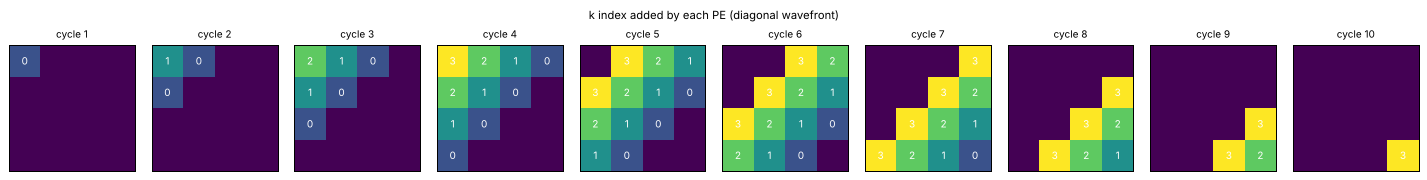

In [8]:
import matplotlib.pyplot as plt

A = np.arange(1, N*N + 1).reshape(N, N)
B = np.eye(N, dtype=int) * 2
_, rows = simulate(A, B, trace=True)
active = [(t, g) for t, g in rows if any(isinstance(x, int) for r in g for x in r)]

fig, axes = plt.subplots(1, len(active), figsize=(1.6 * len(active), 2.0))
for ax, (t, g) in zip(axes, active):
    img = np.array([[x if isinstance(x, int) else np.nan for x in r] for r in g], dtype=float)
    ax.imshow(np.nan_to_num(img, nan=-1), cmap="viridis", vmin=-1, vmax=N - 1)
    for i in range(N):
        for j in range(N):
            if not np.isnan(img[i, j]):
                ax.text(j, i, int(img[i, j]), ha="center", va="center", color="white", fontsize=8)
    ax.set_title(f"cycle {t}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("k index added by each PE (diagonal wavefront)", fontsize=9)
plt.tight_layout()
plt.show()